# Shakespeare with a Tiny GPT

We'll train a small language model to predict the next **character** in Shakespeare. Like the MNIST notebook, we'll load data, define a neural network, choose a loss and optimizer, and train it. Then we'll let it write.

Run the cells in order using the same Python environment as `mnist.ipynb`. The first run downloads the text; later runs use the local copy.

## Importing Code

PyTorch builds and trains our neural network. Matplotlib will let us see whether its loss decreases.

In [2]:
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
torch.set_num_threads(4)

## Using a GPU

We'll use an NVIDIA GPU if CUDA is available, an Apple GPU if MPS is available, or otherwise the CPU. This model is small enough to try on a CPU.

In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print(f"Using device: {device}")

Using device: mps


## Getting Some Data: Shakespeare

We'll use [Tiny Shakespeare](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare), a text collection from Andrej Karpathy's `char-rnn` repository. Unlike MNIST, the data doesn't need separate labels: the character that comes next is the correct answer.

In [4]:
path = Path("data/shakespeare.txt")
if not path.exists():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    with urlopen(url, timeout=30) as response:
        downloaded_text = response.read().decode("utf-8")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(downloaded_text, encoding="utf-8")
text = path.read_text(encoding="utf-8")
print(f"Characters: {len(text):,}")
print(text[:500])

Characters: 1,115,394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## Turning Characters into Numbers

A neural network works with numbers. Our _vocabulary_ contains every distinct character, including spaces, punctuation, and newlines. We assign each character an integer ID. These IDs are labels, not measurements: a larger ID doesn't mean a more important character.

In [5]:
chars = sorted(set(text))
vocab_size = len(chars)
char_to_id = {char: i for i, char in enumerate(chars)}

def encode(s):
    return [char_to_id[char] for char in s]

def decode(ids):
    return "".join(chars[i] for i in ids)

print(f"Vocabulary size: {vocab_size}")
print(repr("".join(chars)))
print(encode("Hello!"))
print(decode(encode("Hello!")))

Vocabulary size: 65
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
[20, 43, 50, 50, 53, 2]
Hello!


## Creating Training Examples

We reserve the last 10% of the text for _validation_, so we can measure performance on text that isn't used to update the weights. We split before making examples so a training example never crosses into validation text.

Each input is a sequence of 64 characters. Its labels are the same sequence shifted one character to the right. At **every position**, the model predicts the next character using only the characters up to that position. A _batch_ contains several randomly selected sequences.

In [6]:
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train, validation = data[:split], data[split:]
context_length = 64
batch_size = 32

def get_batch(data):
    starts = torch.randint(len(data) - context_length, (batch_size,))
    inputs = torch.stack([data[i:i + context_length] for i in starts])
    labels = torch.stack([data[i + 1:i + context_length + 1] for i in starts])
    return inputs.to(device), labels.to(device)

inputs, labels = get_batch(train)
print("Input: ", repr(decode(inputs[0].tolist())))
print("Labels:", repr(decode(labels[0].tolist())))
print("Batch shape:", inputs.shape)

Input:  'lking with a priest, lord chamberlain?\nYour friends at Pomfret, '
Labels: 'king with a priest, lord chamberlain?\nYour friends at Pomfret, t'
Batch shape: torch.Size([32, 64])


## Defining a Tiny GPT

GPT stands for _Generative Pre-trained Transformer_. We'll train a tiny version from scratch. Its main pieces are:

- **Embeddings** turn character IDs and positions into learned vectors.
- **Self-attention** lets each position combine information from earlier positions. A _causal mask_ hides future characters so the model cannot peek at the answers.
- An **MLP** transforms the result at each position. Residual additions (`x + ...`) and layer normalization help training.
- A final **linear layer** produces one score, or _logit_, for each possible next character.

We use two transformer blocks, each with four attention heads. PyTorch handles the attention calculations; the causal mask and the overall GPT structure are explicit below.

In [7]:
class TransformerBlock(nn.Module):
    def __init__(self, hidden_dim, num_heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.attention = nn.MultiheadAttention(hidden_dim, num_heads, batch_first=True)
        self.norm2 = nn.LayerNorm(hidden_dim)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, 4 * hidden_dim),
            nn.GELU(),
            nn.Linear(4 * hidden_dim, hidden_dim),
        )

    def forward(self, x, mask):
        normalized = self.norm1(x)
        attended, _ = self.attention(
            normalized, normalized, normalized, attn_mask=mask, need_weights=False
        )
        x = x + attended
        return x + self.mlp(self.norm2(x))


class GPT(nn.Module):
    def __init__(self, hidden_dim=64, num_heads=4, num_layers=2):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, hidden_dim)
        self.position_embedding = nn.Embedding(context_length, hidden_dim)
        self.blocks = nn.ModuleList([
            TransformerBlock(hidden_dim, num_heads) for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(hidden_dim)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, tokens):
        length = tokens.shape[1]
        positions = torch.arange(length, device=tokens.device)
        x = self.token_embedding(tokens) + self.position_embedding(positions)
        # True entries block attention to future positions.
        mask = torch.ones(length, length, dtype=torch.bool, device=tokens.device).triu(1)
        for block in self.blocks:
            x = block(x, mask)
        return self.output(self.norm(x))

## Visualizing Weights Before and After Training

As in MNIST, **blue means negative, white means zero, and magenta means positive**. Stronger colors mean larger magnitudes. Every square is one weight; no weights are averaged or discarded. Each matrix has its own symmetric color scale, recalculated whenever we plot it. Compare the color-bar numbers as well as the colors before and after training.

- **Embedding matrices:** rows are character IDs or positions; columns are embedding dimensions.
- **Linear matrices:** rows are output units and columns are input units. In the final output layer, rows correspond to character IDs.
- **Attention input projections:** PyTorch stacks the query, key, and value weight matrices vertically. Gray lines separate these three groups. The attention output projection is shown separately. These are learned weights, not attention scores for a particular input.
- Biases and the one-dimensional layer-normalization parameters are omitted, just as biases are omitted in the MNIST plots.

Run this cell to define the drawing function. The calls below display the weights before and after training. A deeper model produces more plots: each transformer block has four weight matrices to display.

In [8]:
def plot_model_weights(model: nn.Module):
    """Draw every weight matrix with square cells and a separate symmetric scale."""
    from matplotlib.colors import LinearSegmentedColormap, Normalize

    cmap = LinearSegmentedColormap.from_list(
        "blue_white_magenta", ["#0000ff", "#ffffff", "#ff00ff"], N=257
    )
    figures = []
    for name, parameter in model.named_parameters():
        if parameter.ndim != 2:
            continue
        matrix = parameter.detach().cpu().float().numpy()
        rows, columns = matrix.shape
        limit = float(abs(matrix).max())
        norm = Normalize(vmin=-(limit or 1.0), vmax=(limit or 1.0))
        figure_height = min(14, max(3, 12 * rows / columns + 1.5))
        figure_width = min(14, max(6, 12 * columns / rows + 2))
        fig, ax = plt.subplots(figsize=(figure_width, figure_height), layout="constrained")
        im = ax.imshow(matrix, cmap=cmap, norm=norm, interpolation="nearest", aspect="equal")
        xlabel, ylabel = "Input unit", "Output unit"
        if name == "token_embedding.weight":
            xlabel, ylabel = "Embedding dimension", "Character ID"
        elif name == "position_embedding.weight":
            xlabel, ylabel = "Embedding dimension", "Position"
        elif name == "output.weight":
            ylabel = "Next-character ID"
        elif name.endswith("in_proj_weight"):
            hidden_dim = rows // 3
            for boundary in (hidden_dim, 2 * hidden_dim):
                ax.axhline(boundary - 0.5, color="gray", linewidth=0.8)
            ax.set_yticks(
                [(i + 0.5) * hidden_dim - 0.5 for i in range(3)],
                ["Query", "Key", "Value"],
            )
            ylabel = "Output units (query / key / value)"
        fig.suptitle(f"{name}\n{rows} rows × {columns} columns")
        ax.set(xlabel=xlabel, ylabel=ylabel)
        orientation = "horizontal" if rows > columns else "vertical"
        fig.colorbar(im, ax=ax, orientation=orientation, shrink=0.8, pad=0.02, label="Weight value")
        figures.append(fig)
        plt.show()
        plt.close(fig)  # Avoid accumulating open figures for deeper models.

    if not figures:
        raise ValueError("The model has no weight matrices to visualize.")
    return figures

## Creating a Language Model

The class above is a template. This cell creates the model with random initial weights and moves it to our chosen device. Rerunning this cell replaces the trained model with a new one.

In [9]:
model = GPT(num_layers=1, hidden_dim=64, num_heads=8).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 62,593


### The Untrained Weights

The model has just been created, so these are random initial weights. Look at the patterns and the color-bar ranges; we'll compare them with the trained weights below.

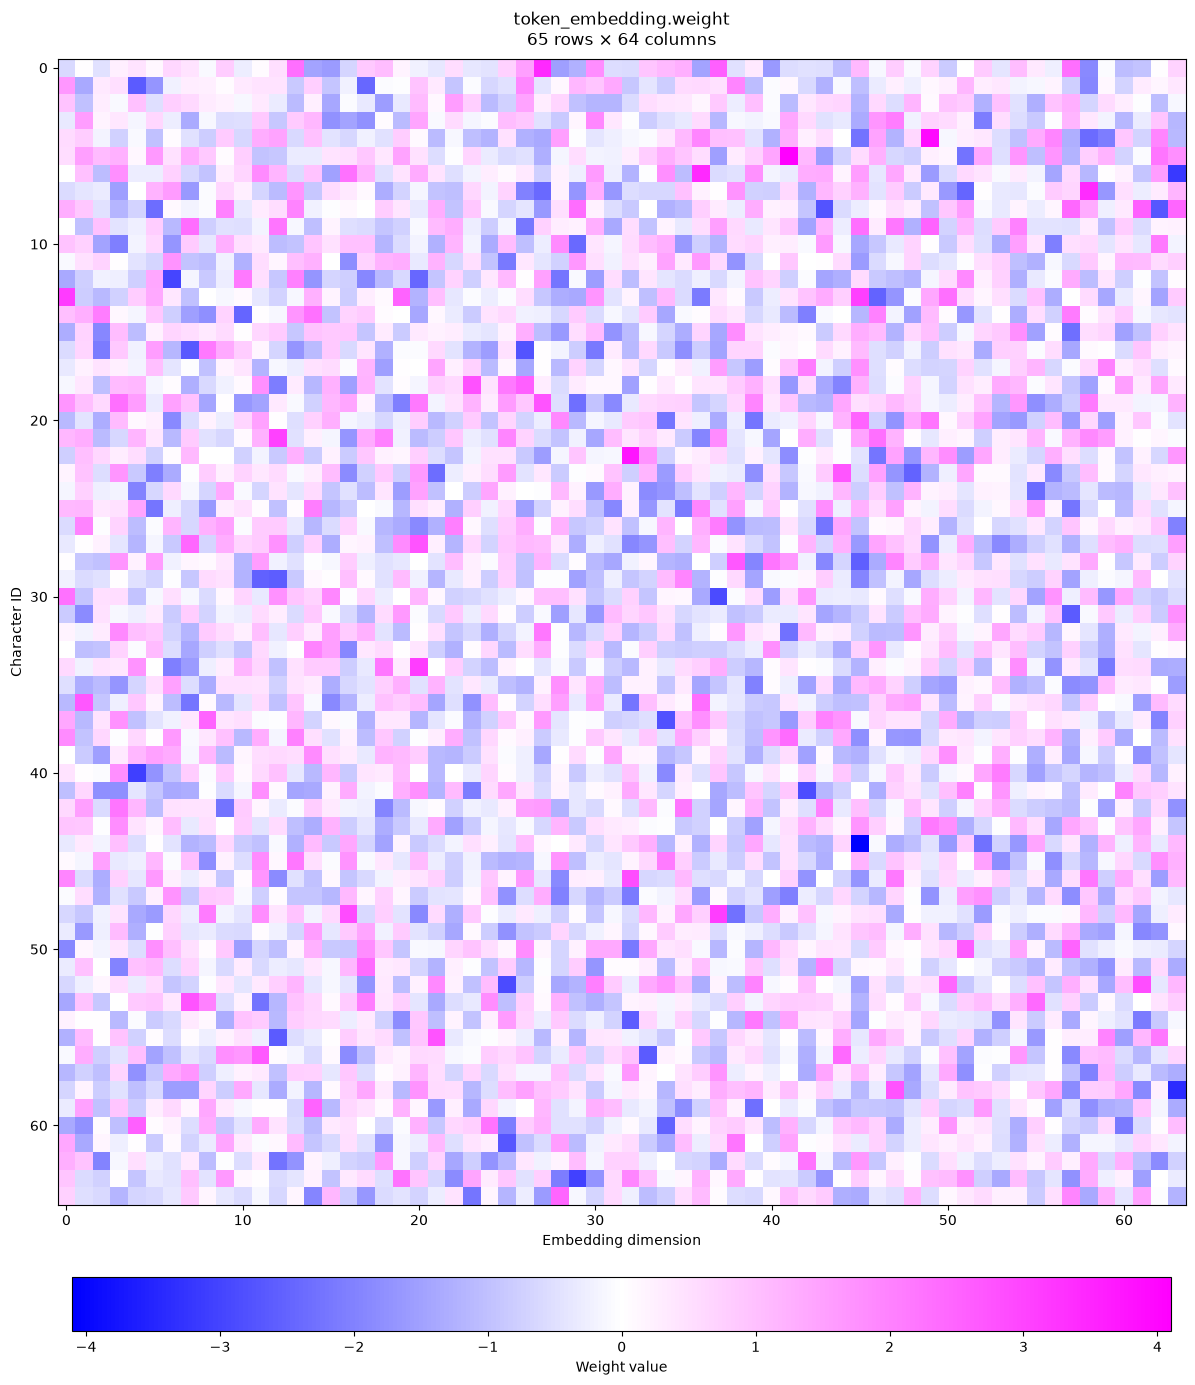

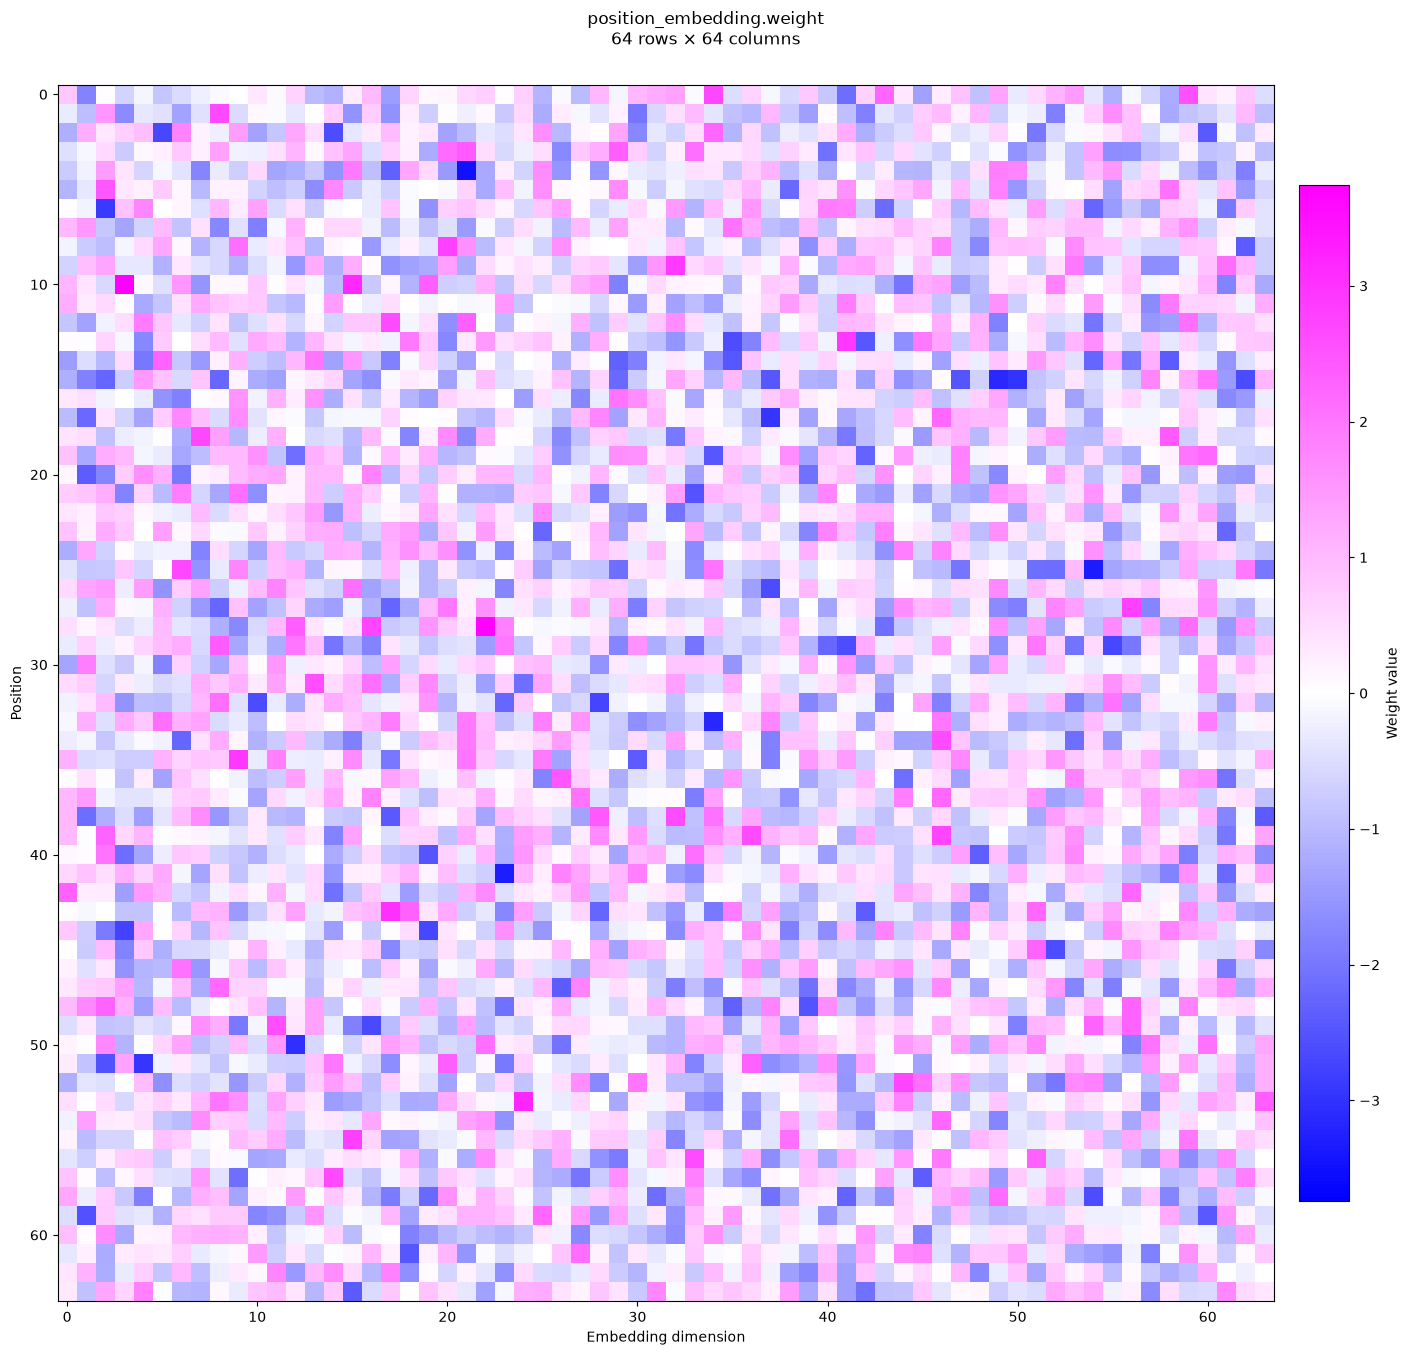

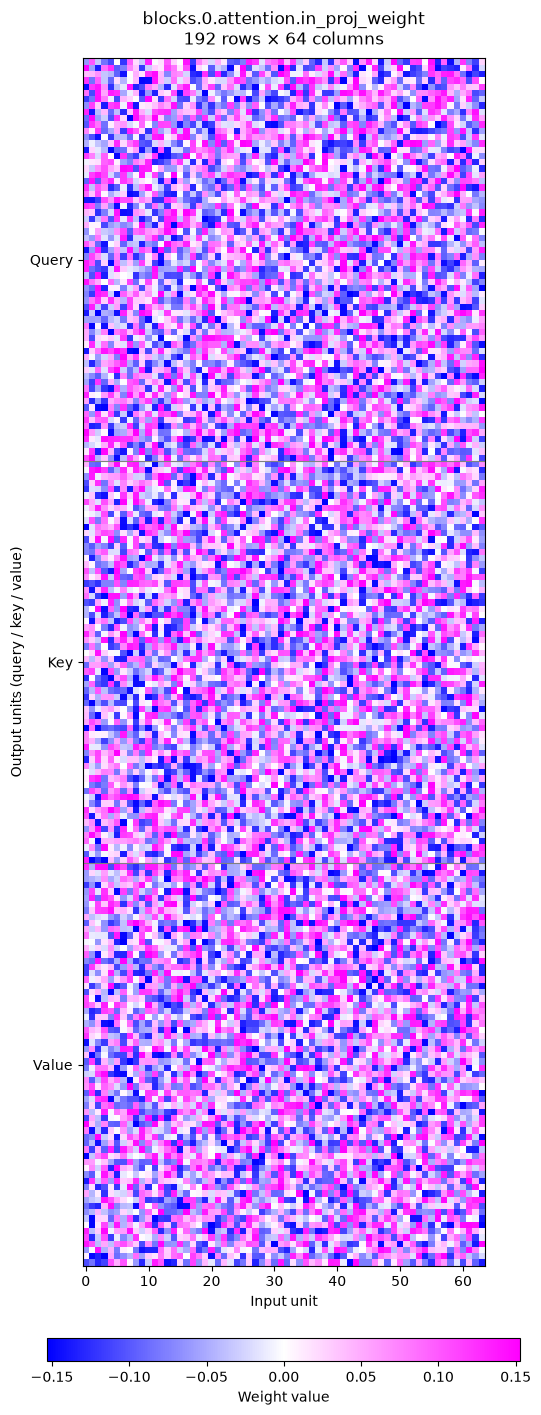

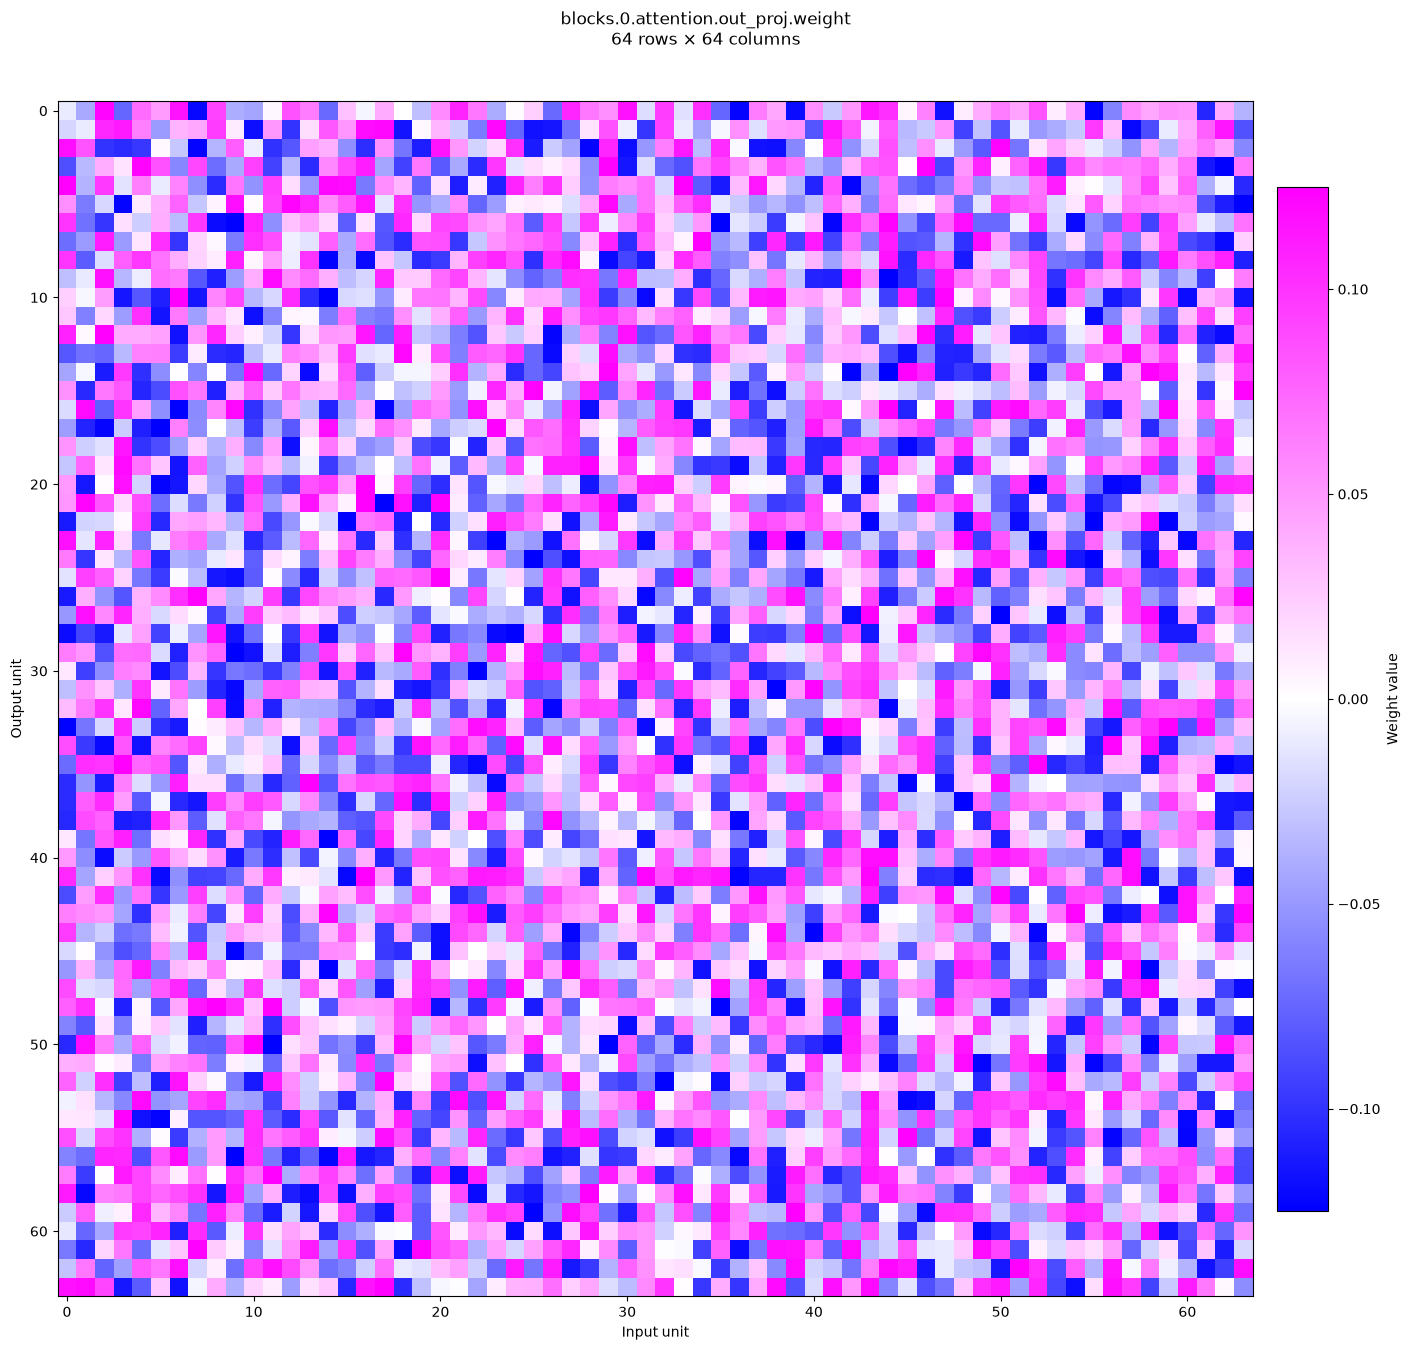

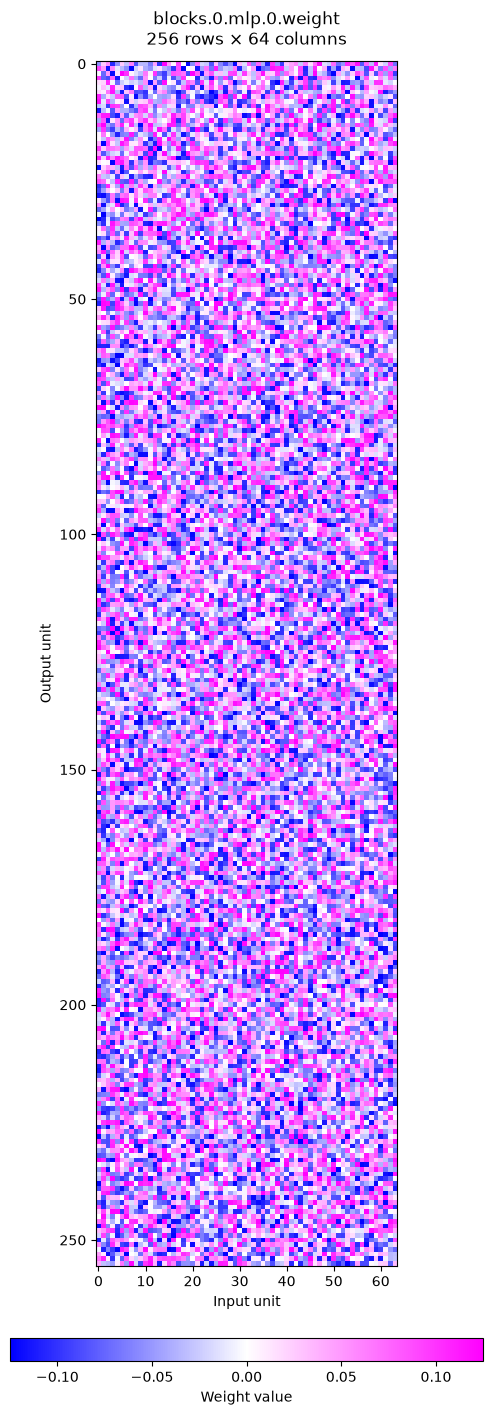

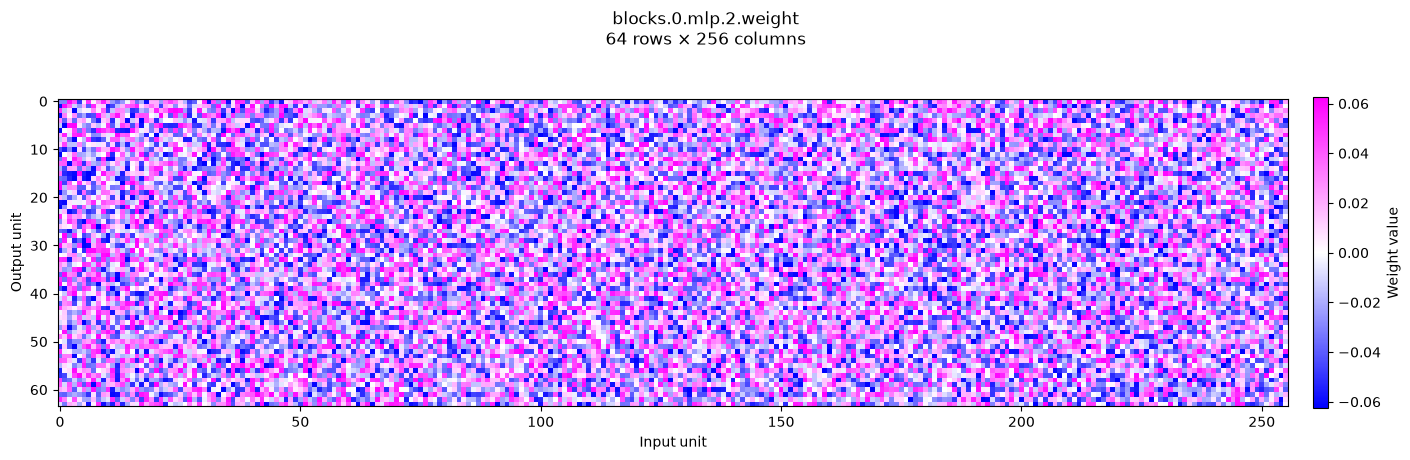

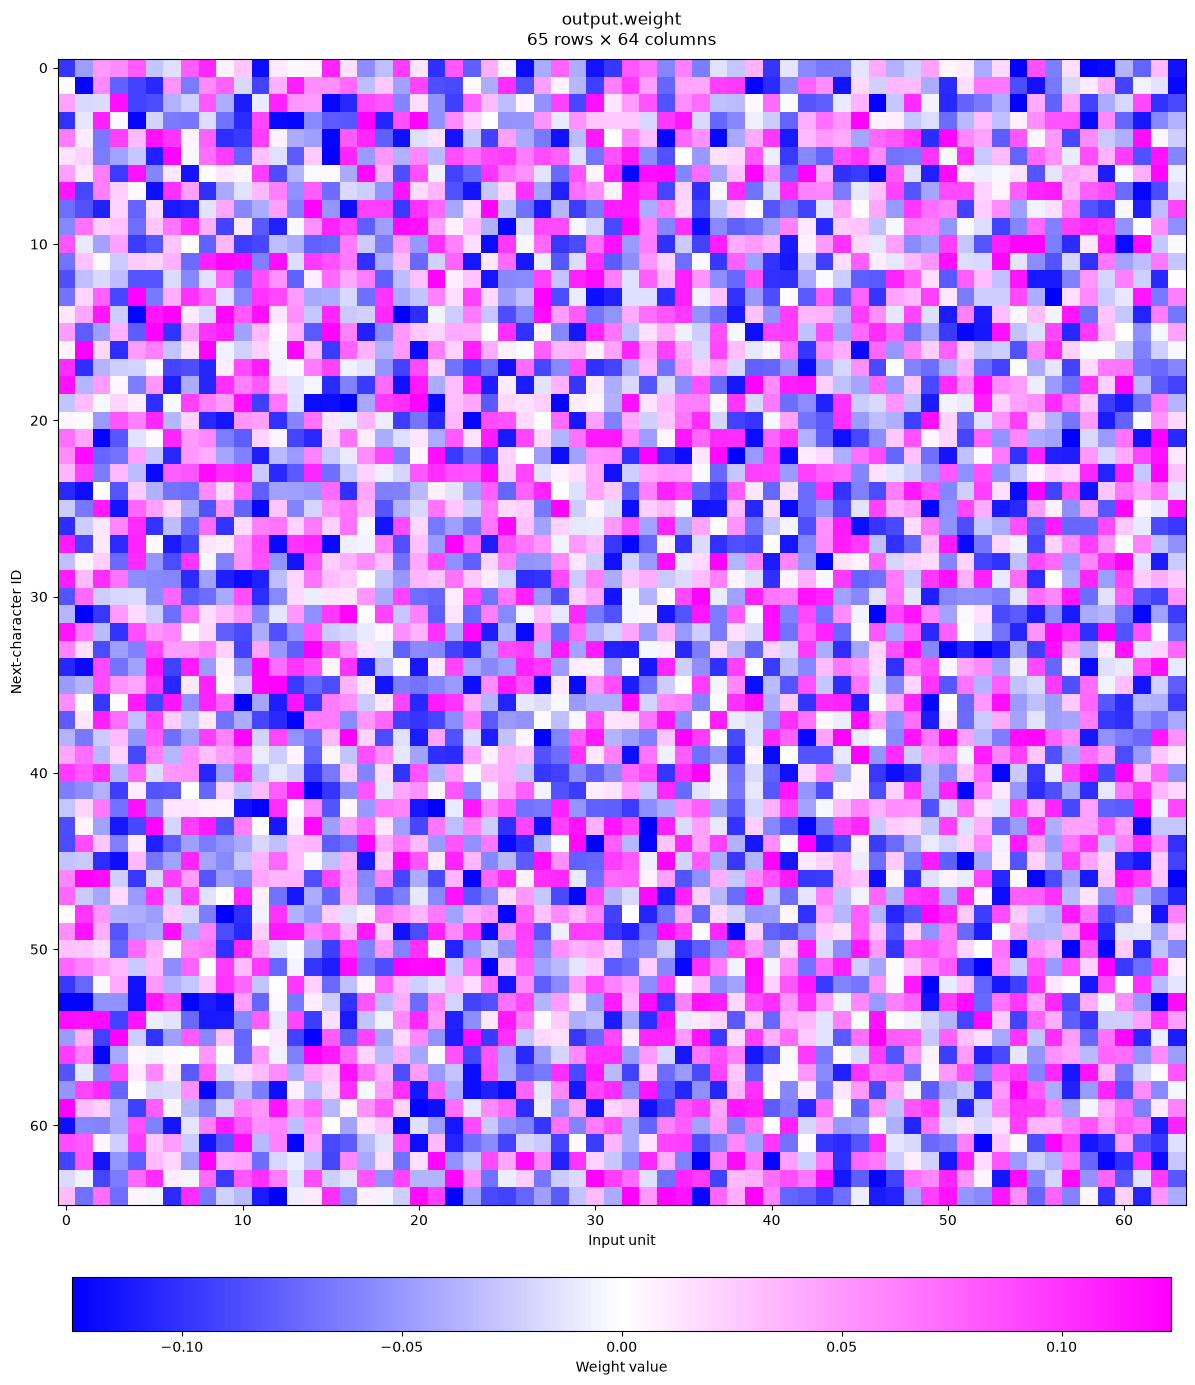

In [10]:
untrained_weight_figures = plot_model_weights(model)

## Defining a Loss and Optimizer

As in MNIST, _cross-entropy loss_ penalizes the model for giving low probability to the correct label. Here the labels are next characters rather than digits. Adam adjusts the weights to reduce that loss.

In [11]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Looking at a Prediction

To generate text, we take the logits at the last input position, use _softmax_ to turn them into probabilities, and sample a character. We append it and repeat, keeping only the most recent 64 characters as context.

The untrained model should produce nonsense. A lower positive `temperature` makes sampling more predictable; a higher value makes it more varied. Prompts must be nonempty and use characters in our vocabulary.

In [12]:
@torch.no_grad()
def generate(prompt, new_characters=300, temperature=1.0):
    if not prompt or temperature <= 0:
        raise ValueError("Use a nonempty prompt and a positive temperature.")
    model.eval()
    tokens = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    for _ in range(new_characters):
        logits = model(tokens[:, -context_length:])[:, -1, :]
        probabilities = torch.softmax(logits / temperature, dim=-1)
        next_token = torch.multinomial(probabilities, num_samples=1)
        tokens = torch.cat([tokens, next_token], dim=1)
    return decode(tokens[0].tolist())

prompt = "ROMEO:\n"
print(generate(prompt))

ROMEO:
;3j AoB;WIPtmkg pe,EB3:IjZzJjJ,phMusstM baEJ
aZ:!Oghu
mi$O'GNe'TFqtlXxVozWf HZQdLQcoApxwIJNh
vE&IHHNp$,qNfnWBywVjvtJj!NLJbzfh!Of.xfD,g$PWfvTxCyZjNhZVcPWOl$WhGV-CN'zfT'ocJt3WtVFtYW&NNwGpHkajZw&--3f asGdLdc HEDNXfnCQ;wVuWz?G;?VUlK$dalyBku;ahGIqDxCjMKW.NMoH?C-QDPsmHMvuaWCHHlnca :gYcP&Q&NrPTesZEf$EffNZC


## The Training Loop

Each step samples a batch, predicts the next characters, measures loss, backpropagates, and updates the weights—just as in MNIST. We flatten the batch and sequence dimensions so cross-entropy treats every position as a classification example.

We count _steps_ instead of epochs because we're randomly sampling text windows rather than making complete passes through the data. Every 100 steps, we estimate loss on 20 batches from each split without updating weights. Lower validation loss means better next-character predictions on held-out text.

Start with 1,000 steps; runtime depends on your device. More steps can improve the text, but this tiny model will still make up words and lose track of meaning.

In [13]:
@torch.no_grad()
def evaluate(data, batches=20):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for _ in range(batches):
        inputs, labels = get_batch(data)
        logits = model(inputs)
        total_loss += loss_fn(logits.reshape(-1, vocab_size), labels.reshape(-1)).item()
        correct += (logits.argmax(dim=-1) == labels).sum().item()
        count += labels.numel()
    return total_loss / batches, correct / count

steps = 1000
history = []
for step in range(steps + 1):
    if step % 100 == 0 or step == steps:
        train_loss, _ = evaluate(train)
        validation_loss, _ = evaluate(validation)
        history.append((step, train_loss, validation_loss))
        print(f"Step {step:4d}: train loss = {train_loss:.3f}, validation loss = {validation_loss:.3f}")
    if step == steps:
        break
    model.train()
    inputs, labels = get_batch(train)
    optimizer.zero_grad()
    logits = model(inputs)
    loss = loss_fn(logits.reshape(-1, vocab_size), labels.reshape(-1))
    loss.backward()
    optimizer.step()

Step    0: train loss = 4.320, validation loss = 4.324
Step  100: train loss = 2.707, validation loss = 2.721
Step  200: train loss = 2.541, validation loss = 2.540
Step  300: train loss = 2.481, validation loss = 2.489
Step  400: train loss = 2.426, validation loss = 2.427
Step  500: train loss = 2.380, validation loss = 2.382
Step  600: train loss = 2.339, validation loss = 2.357
Step  700: train loss = 2.294, validation loss = 2.307
Step  800: train loss = 2.238, validation loss = 2.265
Step  900: train loss = 2.217, validation loss = 2.217
Step 1000: train loss = 2.188, validation loss = 2.204


## Calculate Accuracy, Generate Text

Accuracy counts how often the highest-scoring character matches the next character in the original text. There can be several plausible continuations, so accuracy doesn't tell the whole story. Compare this sample with the untrained output above. You can rerun the generation cell to get another sample without retraining.

In [14]:
validation_loss, accuracy = evaluate(validation)
print(f"Validation loss: {validation_loss:.3f}")
print(f"Next-character accuracy: {accuracy:.2%}")

Validation loss: 2.205
Next-character accuracy: 35.16%


In [15]:
print(generate(prompt, new_characters=500, temperature=0.8))

ROMEO:
Wy thime serale go ast and, sey myend tord on then to she mad witn:
Cis do hat the me lith creatis imed hy I pron, edads mave sto melin hoe by, by he thed prand
Therie wing of ading of makeath--
Imours this
HEN:
I pit dean, bend?
INICEN Saurken nor 'd
BENIUS:
And alave my we and but withis you.

SNUSSTHONTYINE VENENENIAMESIS:
WABERNINANE:
ARINCENC:
NG semy wong che wornd knouendive you be;
I wout and cheat the pad eath thall gorse hey meres ushiry ther page seris anee gind prand bove liel fo swe


### The Trained Weights

Run the same function on the trained model. What patterns have appeared or changed? The color scales are recalculated for each plot, so compare their numbers too.

You can rerun this plotting cell without retraining. Rerunning the cell under "Creating a Language Model" would replace your trained model with a new, untrained one.

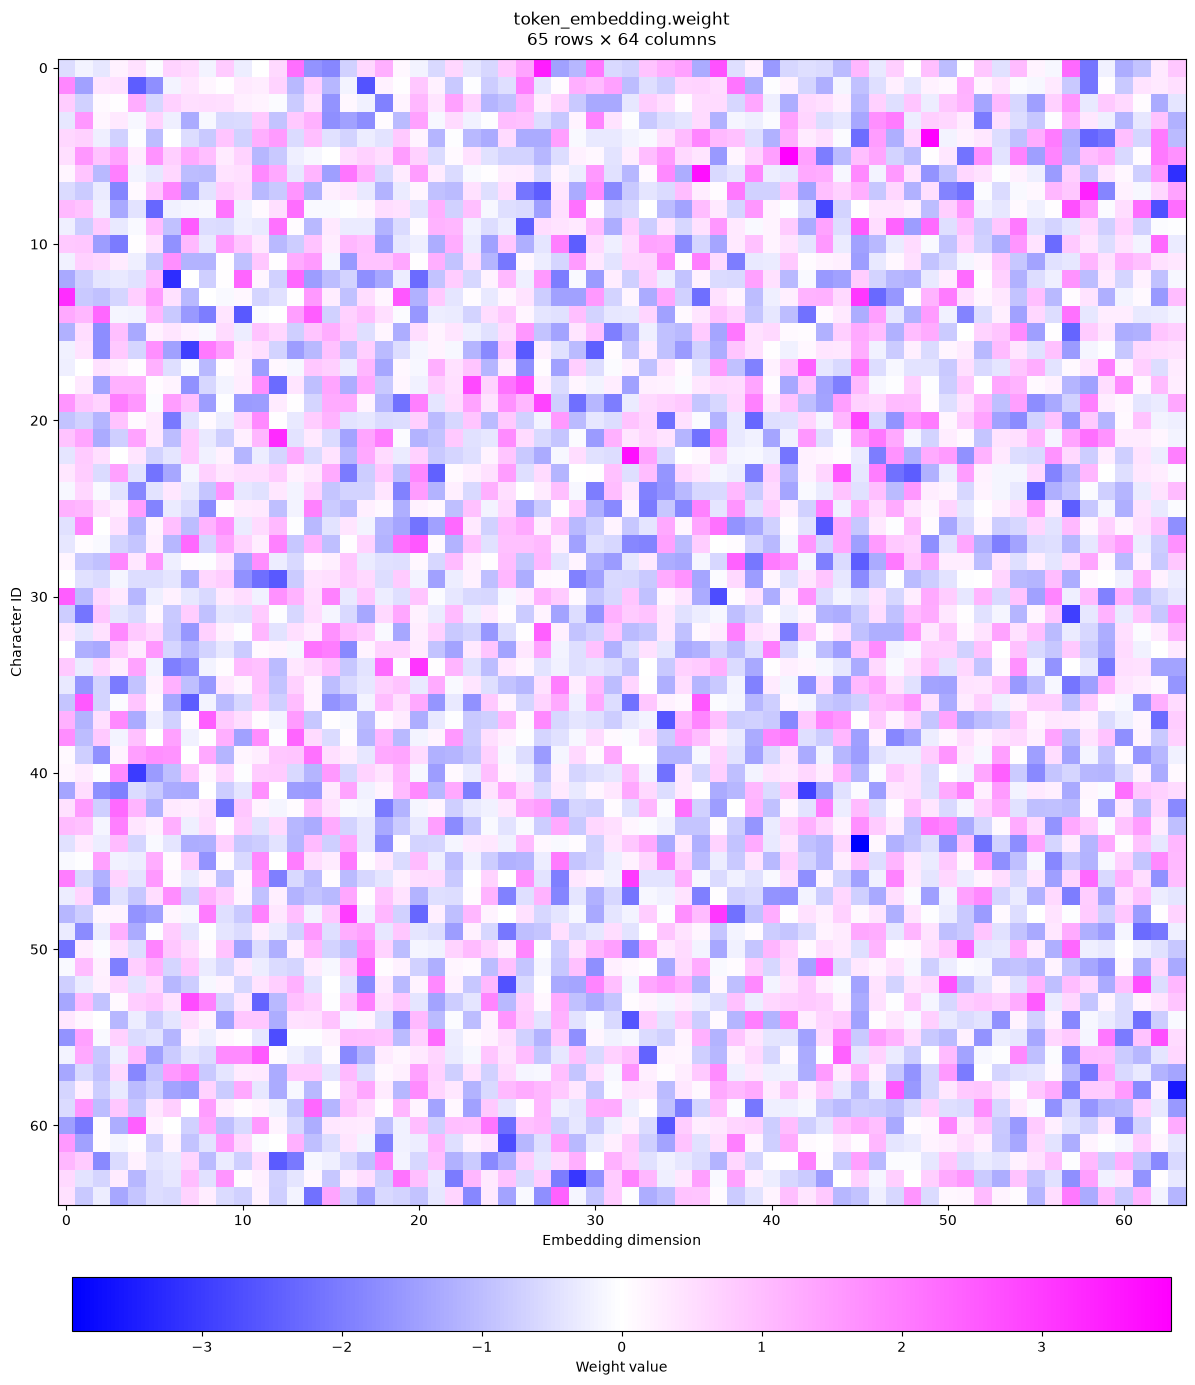

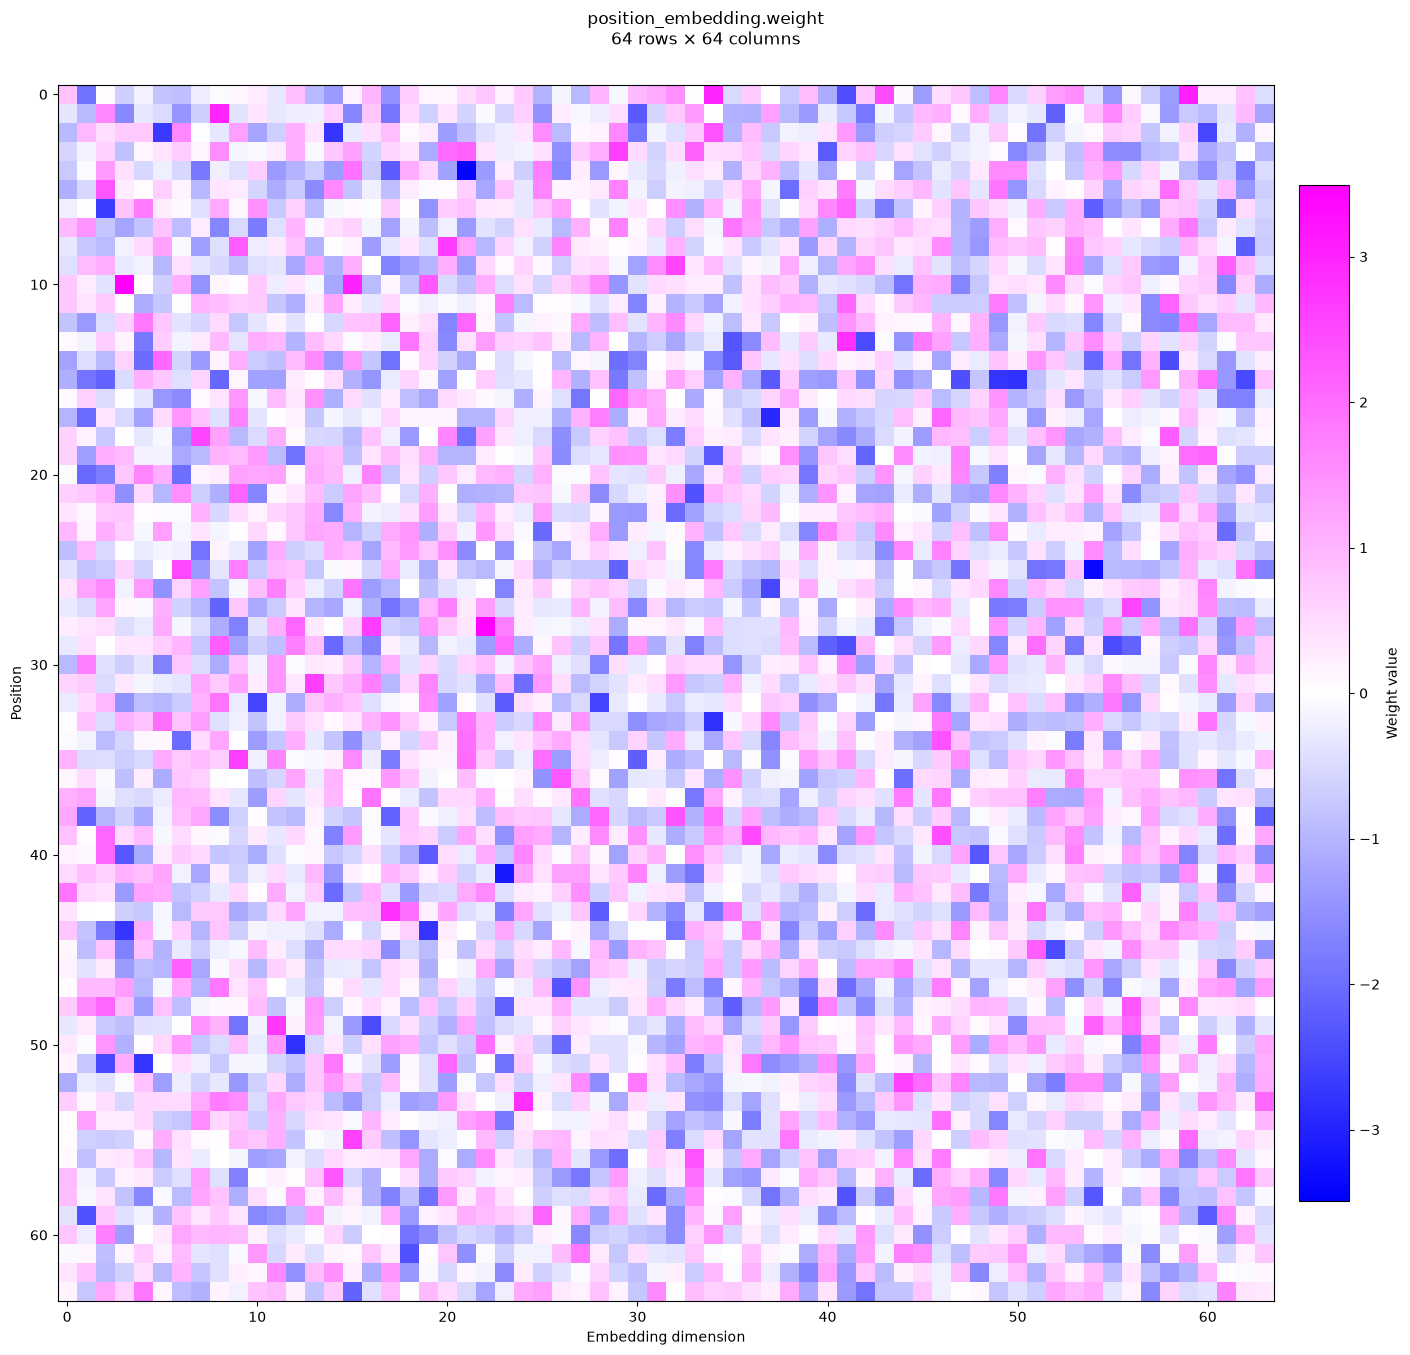

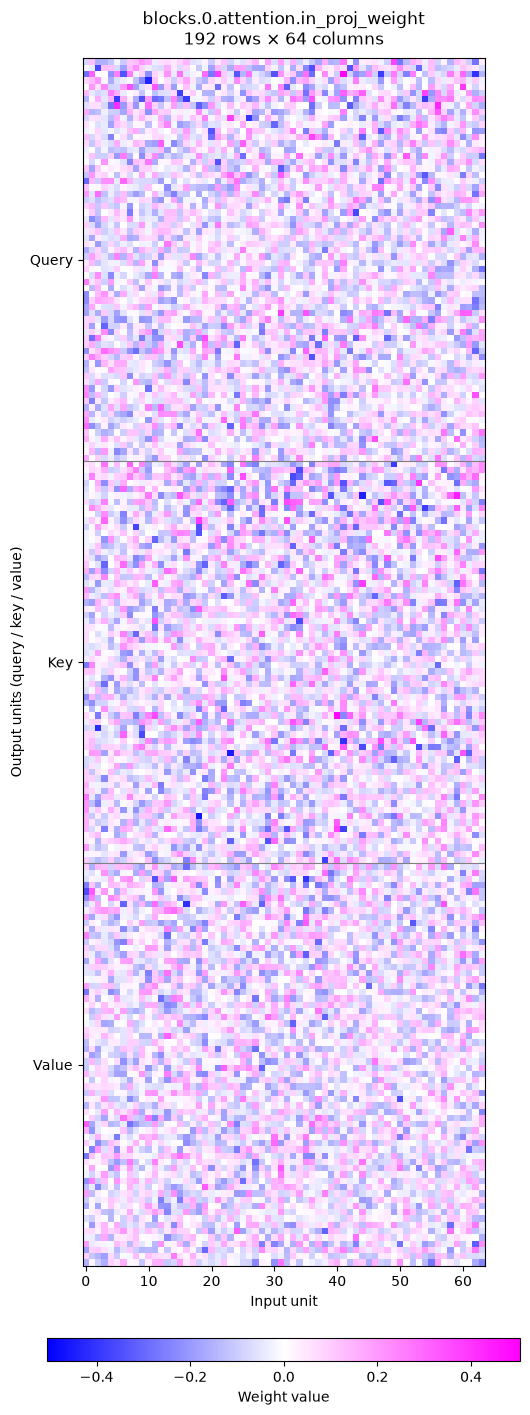

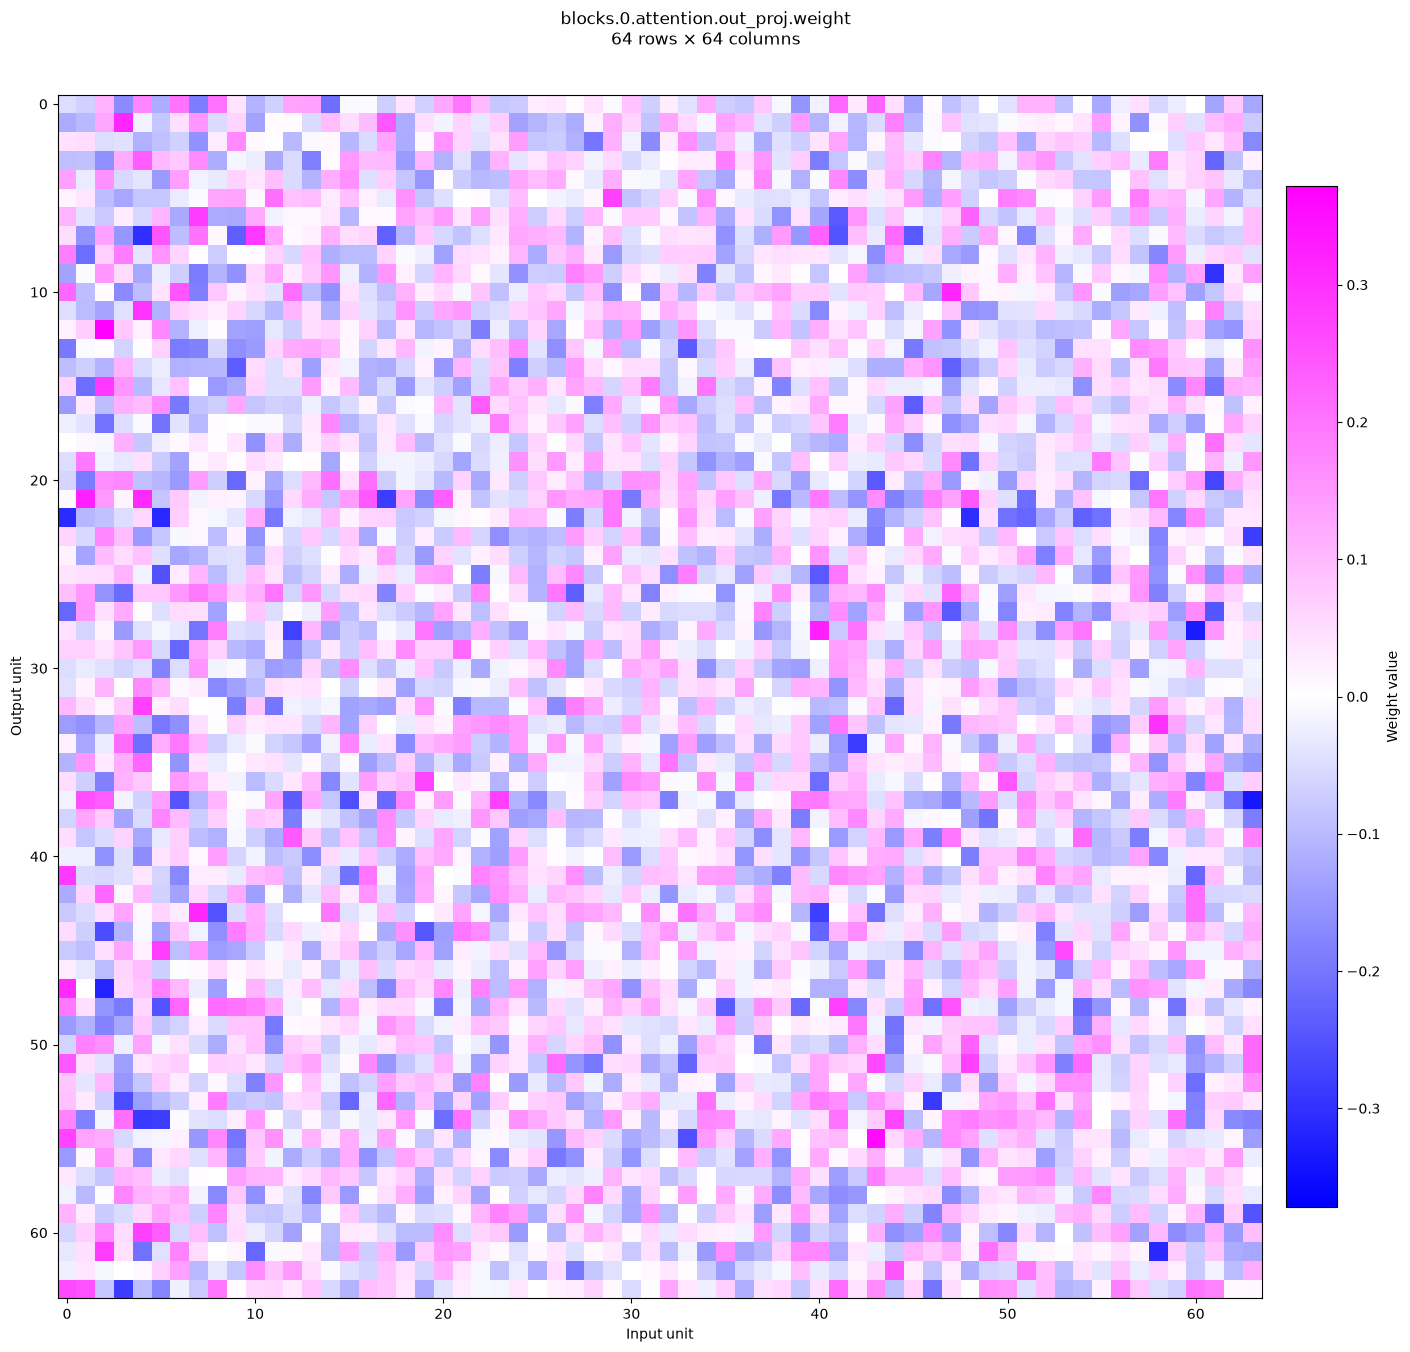

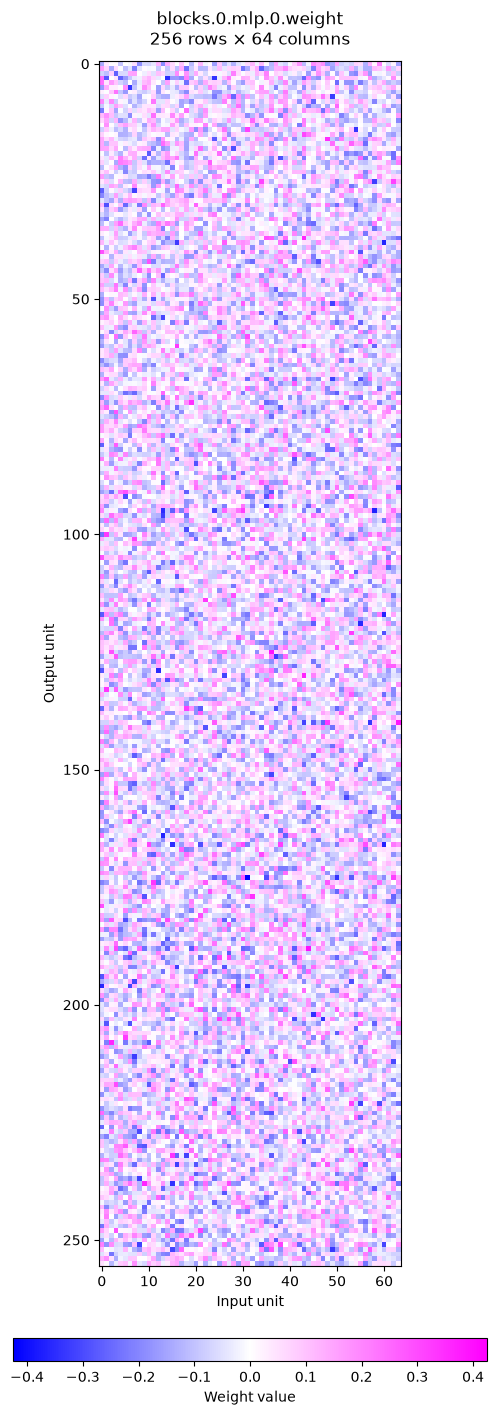

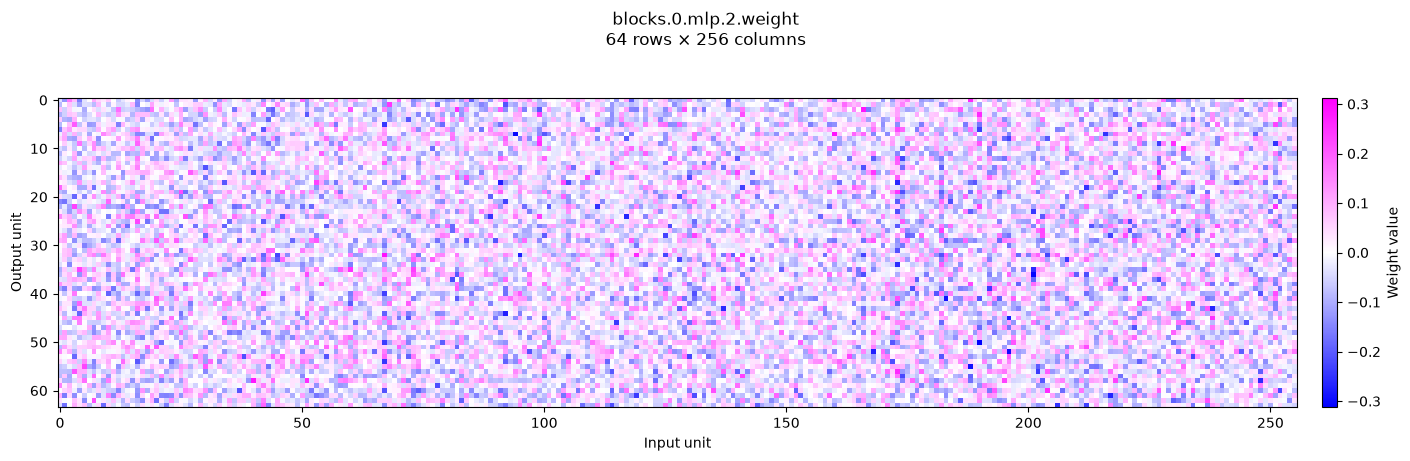

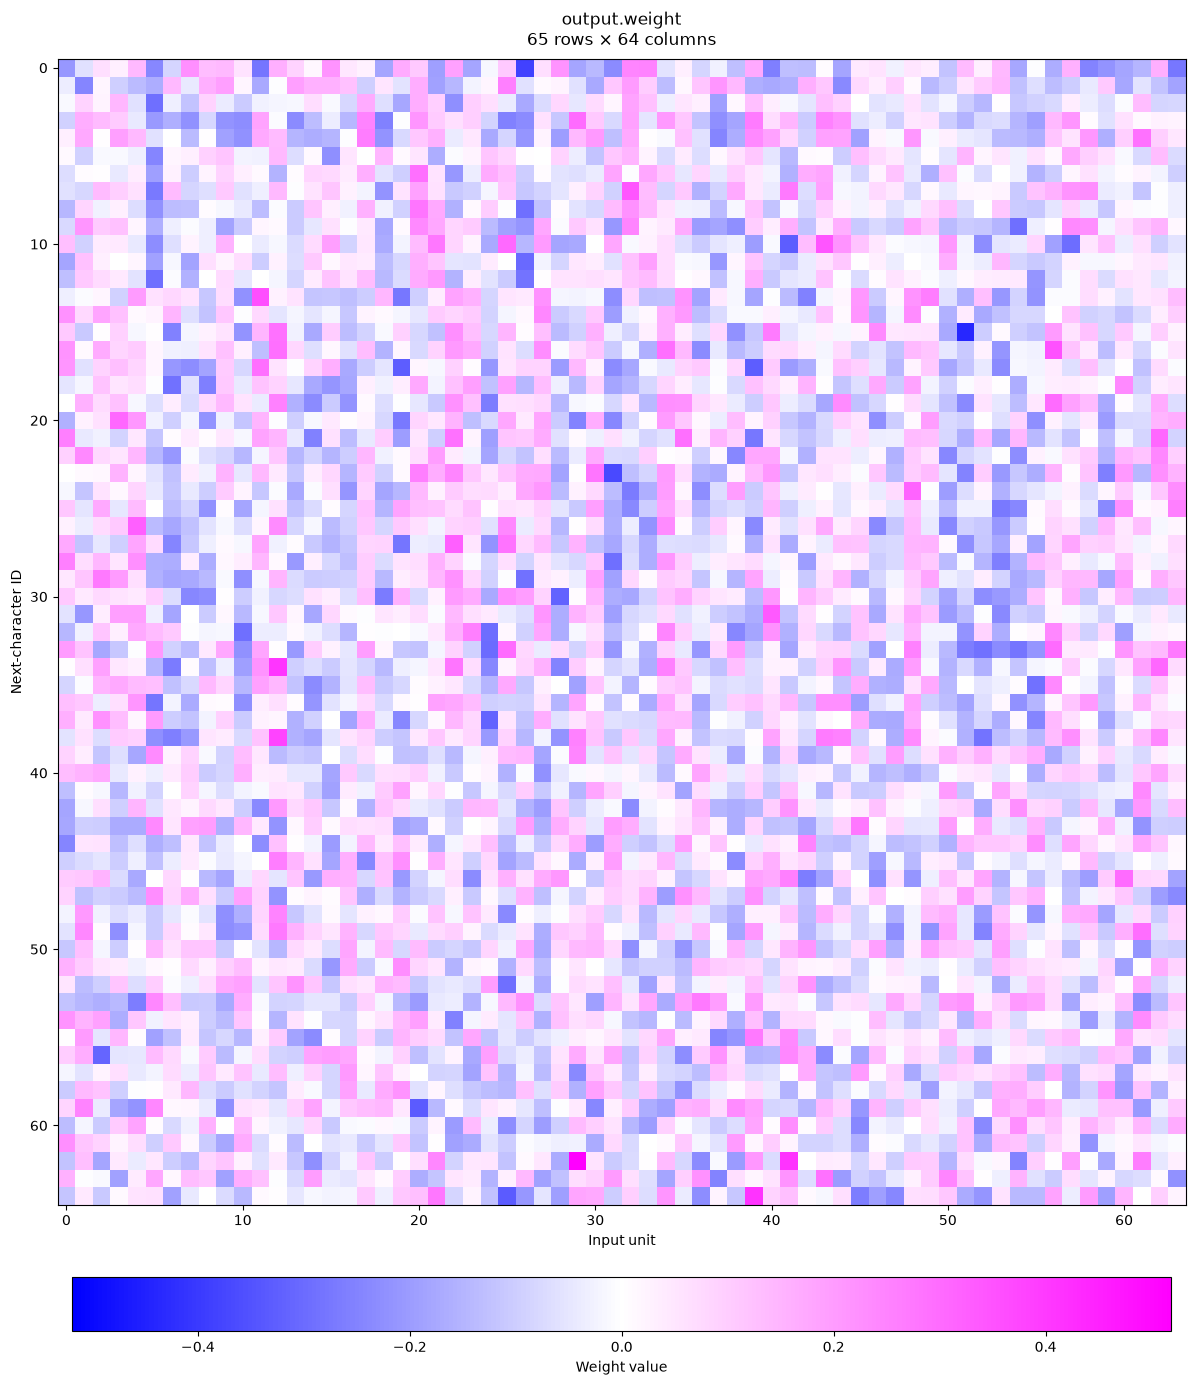

In [16]:
trained_weight_figures = plot_model_weights(model)

## Visualizing Learning

Both losses should generally fall. If training loss keeps falling while validation loss rises, the model may be _overfitting_: learning details of the training text that don't help with unseen text.

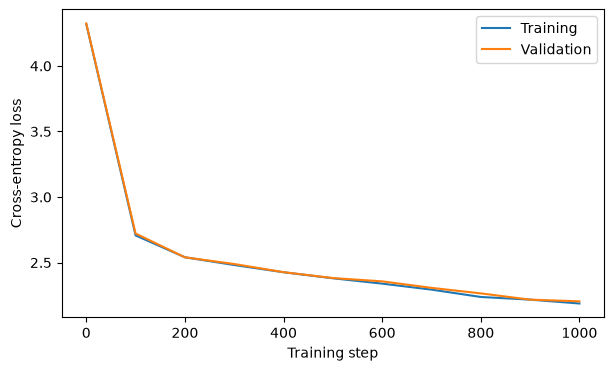

In [17]:
training_steps, train_losses, validation_losses = zip(*history)
plt.figure(figsize=(7, 4))
plt.plot(training_steps, train_losses, label="Training")
plt.plot(training_steps, validation_losses, label="Validation")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()